#### Requirements

In [1]:
import pandas as pd
import numpy as np

import sys
sys.path.append("../..")

from src.backtester import calculate_return, backtester, backtester_v2
from src.strategies import run_momentum_strategy
from src.summary import summary

In [2]:
df = pd.read_csv("../../data/spy_daily.csv")
prices = df["Adj Close"]
returns = calculate_return(prices)
lookback = 252

returns_array = np.array(returns)
prices_array = np.array(prices)

In [3]:
momentum_df, momentum_results = run_momentum_strategy(prices, returns, lookback, 0.001)

In [4]:
time_invested = momentum_results["time_invested"]

#### Exposure Matched Random Strategies

In [5]:
def generate_random_signal_v2(prices, lookback):

    random_signal = [np.nan] * lookback

    choice = np.random.choice([0,1], size = len(prices) - lookback, p = [1 - time_invested,time_invested])

    random_signal = random_signal + choice.tolist()

    return random_signal

In [6]:
def generate_random_signal_optimised(prices_array, lookback):

    choice = np.random.choice([0,1], size = len(prices) - lookback, p = [1 - time_invested,time_invested])

    random_signal_array = np.empty_like(prices_array)
    random_signal_array[:lookback] = np.nan
    random_signal_array[lookback:] = choice

    return random_signal_array

In [7]:
df["Random Signal"] = generate_random_signal_v2(prices, lookback)
random_signal = df["Random Signal"]

random_df, random_result = backtester(returns, random_signal, 0.001)
pd.Series(random_result)

total_return           -0.428769
cagr                   -0.021607
annual_volatility       0.166609
annual_sharpe          -0.047561
max_drawdown           -0.720400
calmar                 -0.029993
time_invested           0.777554
trades               2243.000000
dtype: float64

In [8]:
def run_simulation_v2(n):

    simulation_result = []

    for i in range(n):

        random_signal = generate_random_signal_v2(prices, lookback)
        _, random_result = backtester(returns, random_signal, 0.001)

        simulation_result.append(random_result)

    return simulation_result



In [9]:
def run_simulation_v2_optimised(n):

    simulation_result = []

    for i in range(n):

        random_signal = generate_random_signal_v2(prices, lookback)
        random_result = backtester_v2(returns, random_signal, 0.001)

        simulation_result.append(random_result)

    return simulation_result

In [10]:
np.random.seed(44)

simulation_output = run_simulation_v2_optimised(100000)
simulation_df = pd.DataFrame(simulation_output)
simulation_df

,total_return,cagr,annual_volatility,annual_sharpe,max_drawdown,calmar,time_invested,trades
0,-0.575245,-0.032850,0.165722,-0.118693,-0.704884,-0.046603,0.775387,2261
1,-0.597904,-0.034916,0.170442,-0.123208,-0.682150,-0.051185,0.778483,2250
2,-0.535162,-0.029442,0.164602,-0.099071,-0.752120,-0.039145,0.771672,2311
3,-0.361064,-0.017322,0.165845,-0.022277,-0.705379,-0.024558,0.772755,2289
4,-0.314679,-0.014632,0.167466,-0.004329,-0.701865,-0.020848,0.769350,2326
...,...,...,...,...,...,...,...,...
99995,-0.400128,-0.019738,0.165130,-0.038144,-0.677660,-0.029126,0.764706,2363
99996,-0.826409,-0.066027,0.164257,-0.333387,-0.868929,-0.075986,0.763003,2369
99997,-0.444347,-0.022662,0.170376,-0.049216,-0.720354,-0.031459,0.772910,2239
99998,-0.490937,-0.025995,0.170264,-0.069527,-0.764482,-0.034003,0.770124,2257


Mean Sharpe: -0.03615
Median Sharpe: -0.03647
Max Sharpe: 0.38073
P Value: 0.00001
Avg Trades: 2251.87858
Avg Time Invested: 0.77521
Number Of Simulations: 100000


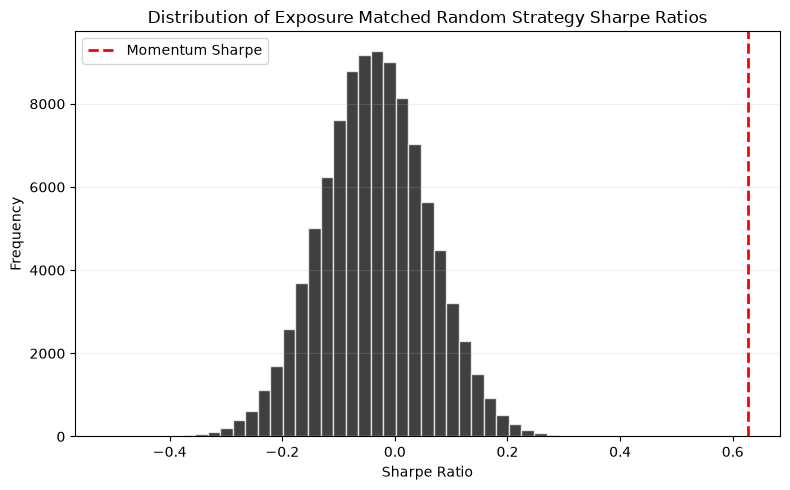

In [11]:
exposure_matched_summary = summary(simulation_df, momentum_results, "exposure_matched_random_strategy")